<a href="https://colab.research.google.com/github/Research-methods-group5/Hackathon_groupO/blob/main/hackthon_0_24086678.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [97]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets

train = pd.read_csv('/content/dataset_C_training.csv')
test = pd.read_csv('/content/dataset_C_testing.csv')

# Display dataset dimensions

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

# Display first five rows

display(train.head())

Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


In [98]:
# Cell 2 – Understand the dataset
# Dataset information

train.info()

# Statistical summary

display(train.describe(include='all').T)

# Check missing values

missing = train.isnull().sum()

print("Missing values:")
display(missing[missing > 0].sort_values(ascending=False))

# Check duplicate records

print("Duplicate rows:", train.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance               2848 non-null   f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0


Missing values:


,0
employment_sector,2330
health_insurance,1908
income_poverty,748
rent_or_own,329
employment_status,238
marital_status,231
education,228
child_under_6_months,135
health_worker,132
opinion_covid_sick_from_vacc,90


Duplicate rows: 0


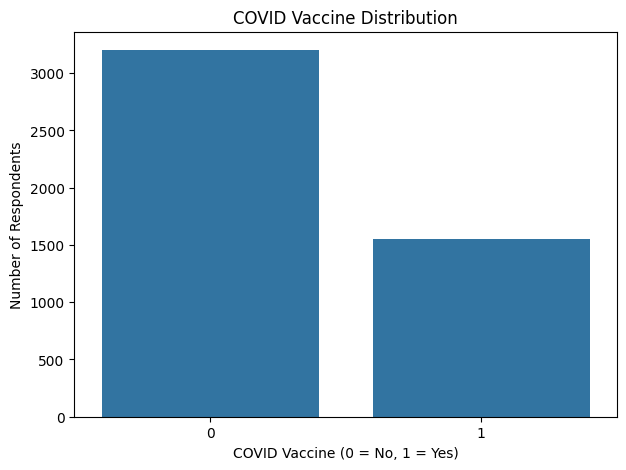

In [99]:
# Cell 3 – Visualise target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=train, x='covid_vaccine')

plt.title('COVID Vaccine Distribution')
plt.xlabel('COVID Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Number of Respondents')

plt.show()


In [100]:
# Cell 4 – Check unusual values
# Check zero values in opinion columns

opinion_columns = [
    'opinion_covid_vacc_effective',
    'opinion_covid_risk'
]

for col in opinion_columns:
    print("\n", col)
    print(train[col].value_counts().sort_index())


 opinion_covid_vacc_effective
opinion_covid_vacc_effective
0      92
1     124
2     241
3     772
4    2425
5    1102
Name: count, dtype: int64

 opinion_covid_risk
opinion_covid_risk
0      96
1    1196
2    1228
3     982
4    1029
5     225
Name: count, dtype: int64


In [101]:
# Cell 5 – Replace invalid zeros with missing values
# Convert invalid zero values into NaN

opinion_columns = [
    'opinion_covid_vacc_effective',
    'opinion_covid_risk'
]

for col in opinion_columns:
    train[col] = train[col].replace(0, np.nan)
    test[col] = test[col].replace(0, np.nan)

# Check the results

for col in opinion_columns:
    print("\n", col)
    print(train[col].value_counts(dropna=False).sort_index())


 opinion_covid_vacc_effective
opinion_covid_vacc_effective
1.0     124
2.0     241
3.0     772
4.0    2425
5.0    1102
NaN      92
Name: count, dtype: int64

 opinion_covid_risk
opinion_covid_risk
1.0    1196
2.0    1228
3.0     982
4.0    1029
5.0     225
NaN      96
Name: count, dtype: int64


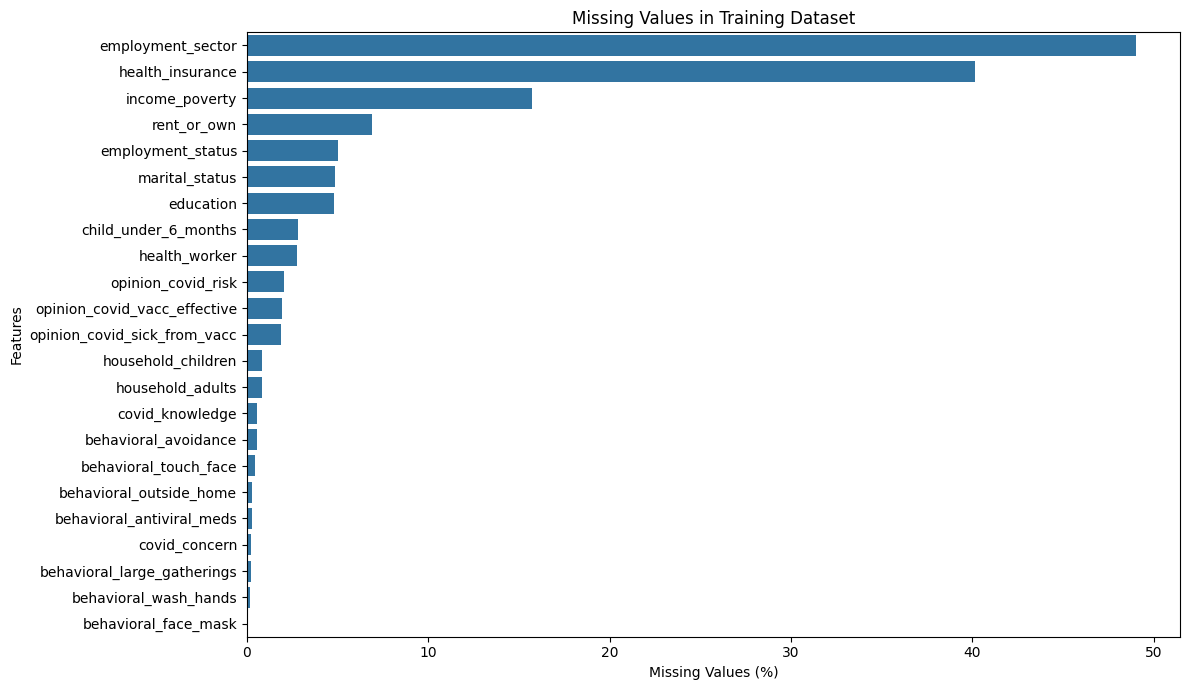

In [102]:
# 3. Next: Missing-value visualisation
# Cell 6 – Plot missing values
missing_percent = (
    train.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[missing_percent > 0]

plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title('Missing Values in Training Dataset')
plt.xlabel('Missing Values (%)')
plt.ylabel('Features')
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [103]:
# Check the distribution of the target variable

print(train['covid_vaccine'].value_counts())

# Display percentages
print("\nTarget variable percentages:")
print(train['covid_vaccine'].value_counts(normalize=True) * 100)

covid_vaccine
0    3202
1    1554
Name: count, dtype: int64

Target variable percentages:
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


In [104]:

# Cell 7 – Target variable distribution

# Count the number of respondents in each class
target_counts = train['covid_vaccine'].value_counts().sort_index()

# Calculate percentages
target_percentages = train['covid_vaccine'].value_counts(
    normalize=True
).sort_index() * 100

# Display results
target_summary = pd.DataFrame({
    'Number of Respondents': target_counts,
    'Percentage (%)': target_percentages
})

display(target_summary)


,Number of Respondents,Percentage (%)
covid_vaccine,,
0,3202,67.325484
1,1554,32.674516


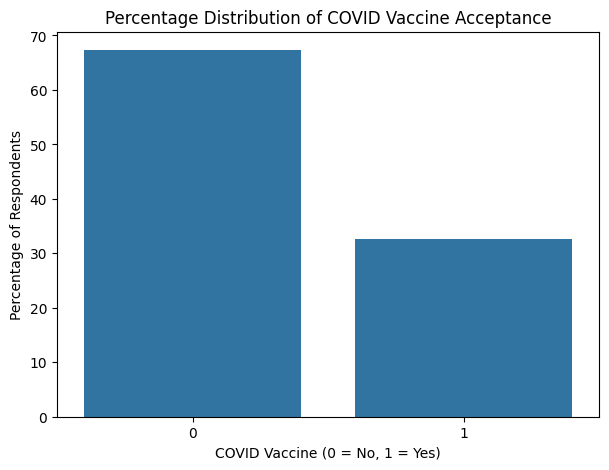

In [105]:

# Cell 8 – Visualise target percentages

plt.figure(figsize=(7, 5))

sns.barplot(
    x=target_percentages.index,
    y=target_percentages.values
)

plt.title('Percentage Distribution of COVID Vaccine Acceptance')
plt.xlabel('COVID Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Percentage of Respondents')

plt.savefig(
    'target_distribution_percentage.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [106]:

# Cell 9 – Identify categorical and numerical columns

categorical_columns = train.select_dtypes(
    include=['object']
).columns.tolist()

numerical_columns = train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)


Categorical columns:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

Numerical columns:
['respondent_id', 'covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions', 'covid_vaccine']


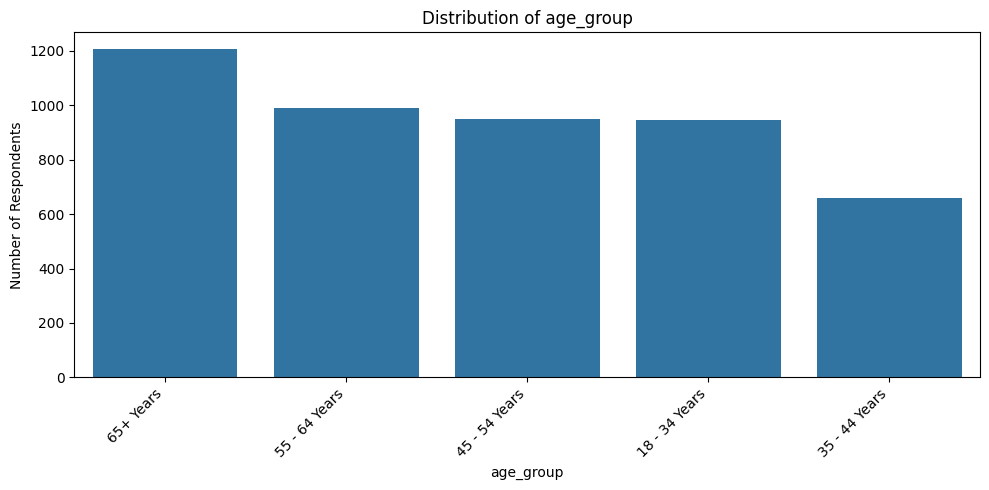

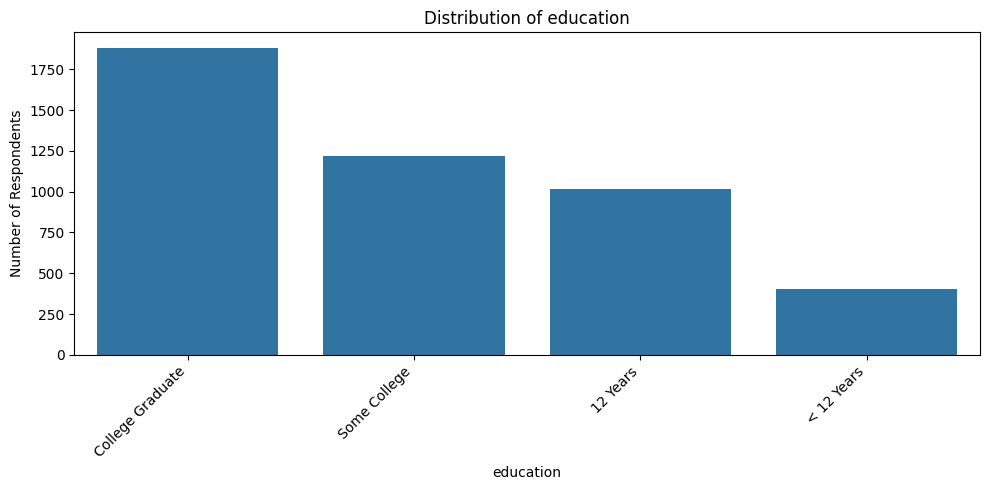

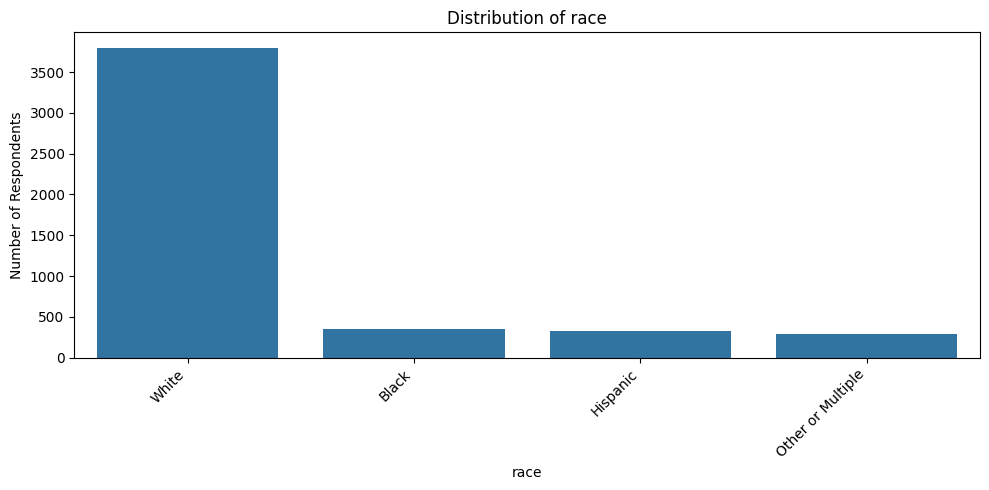

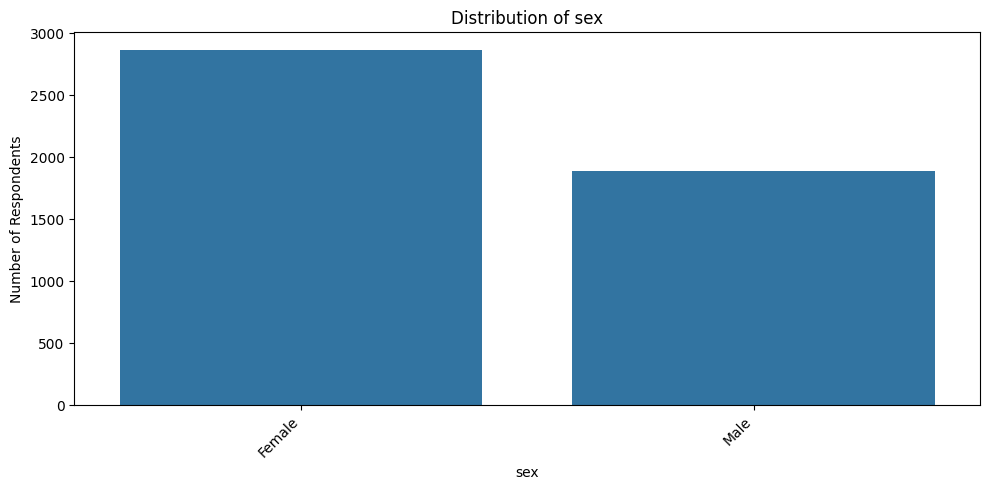

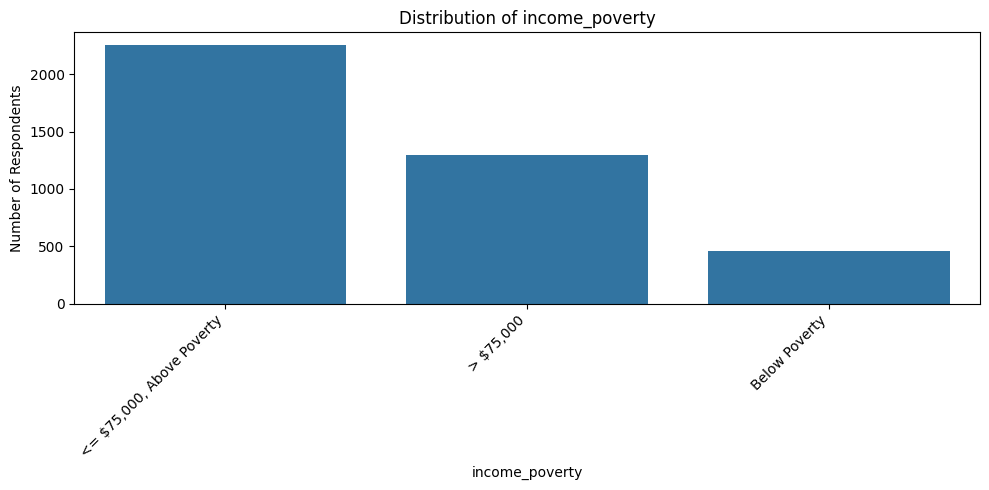

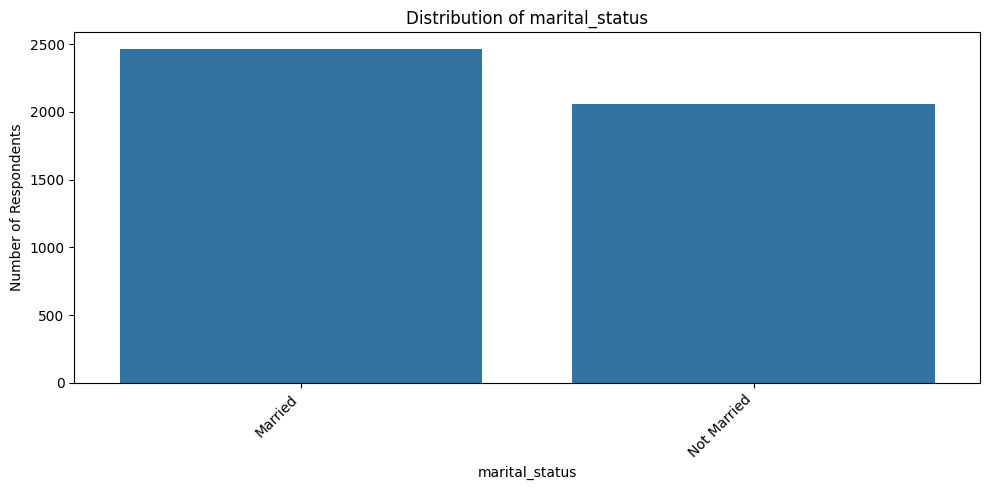

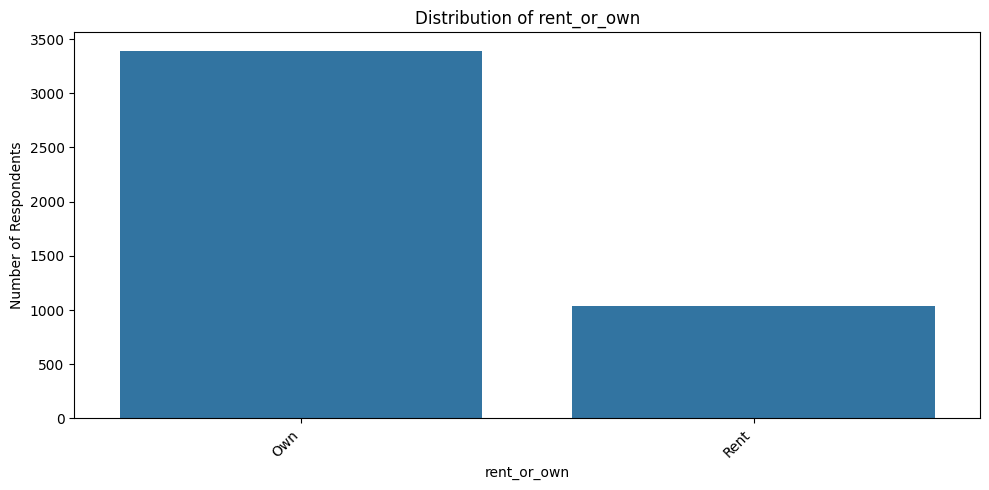

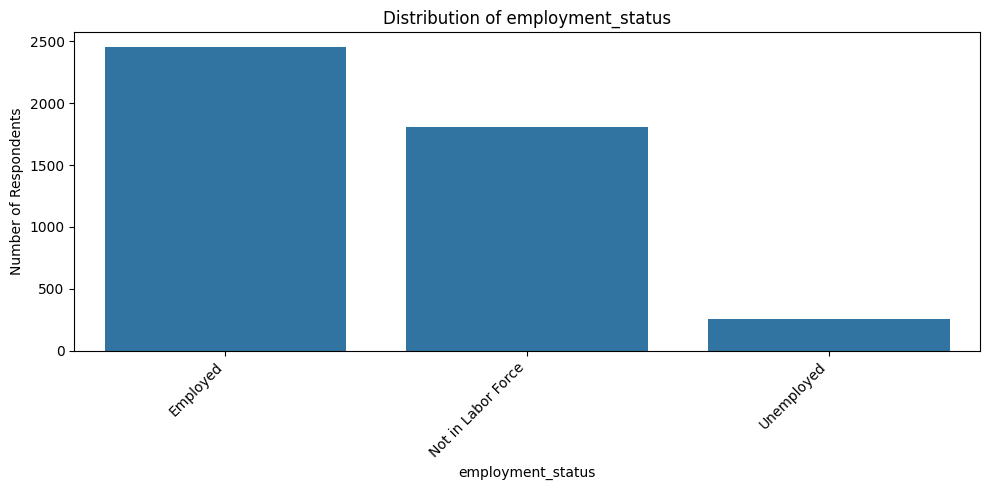

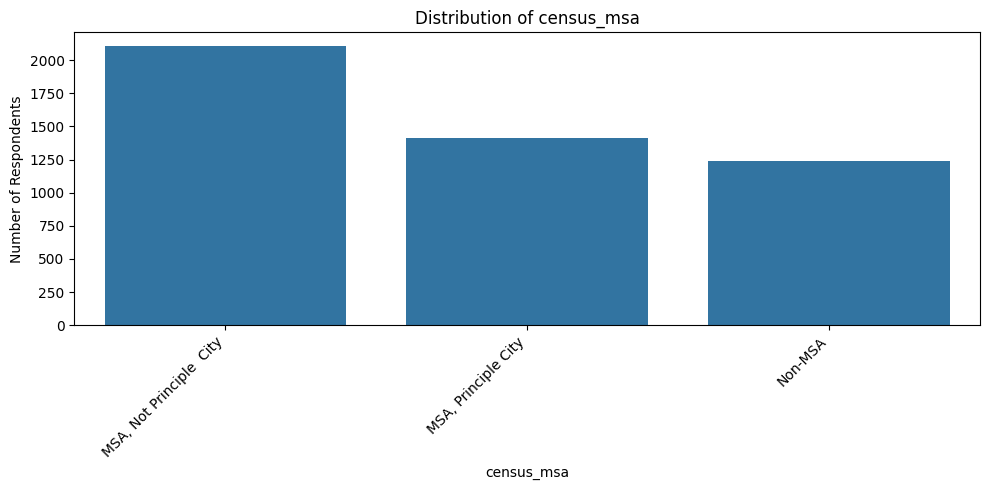

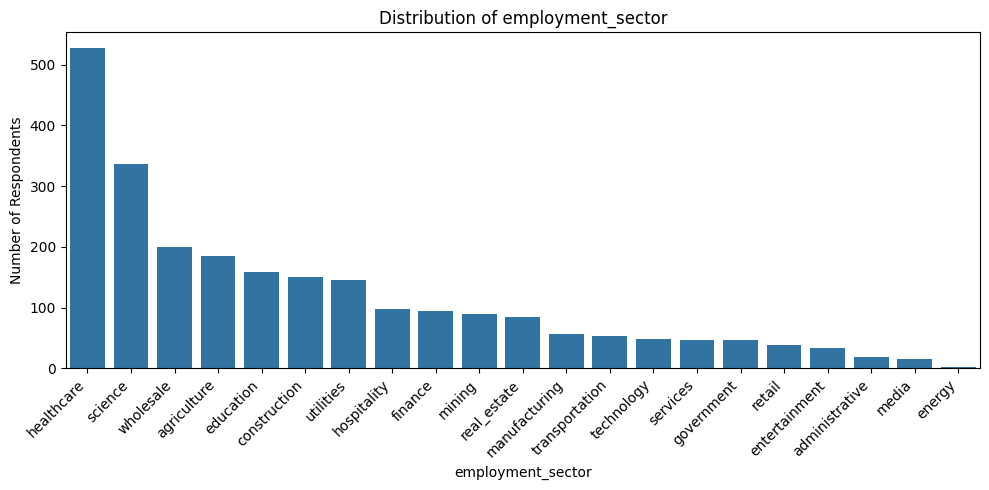

In [107]:

# Cell 10 – Visualise categorical features

for col in categorical_columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train,
        x=col,
        order=train[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Respondents')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()


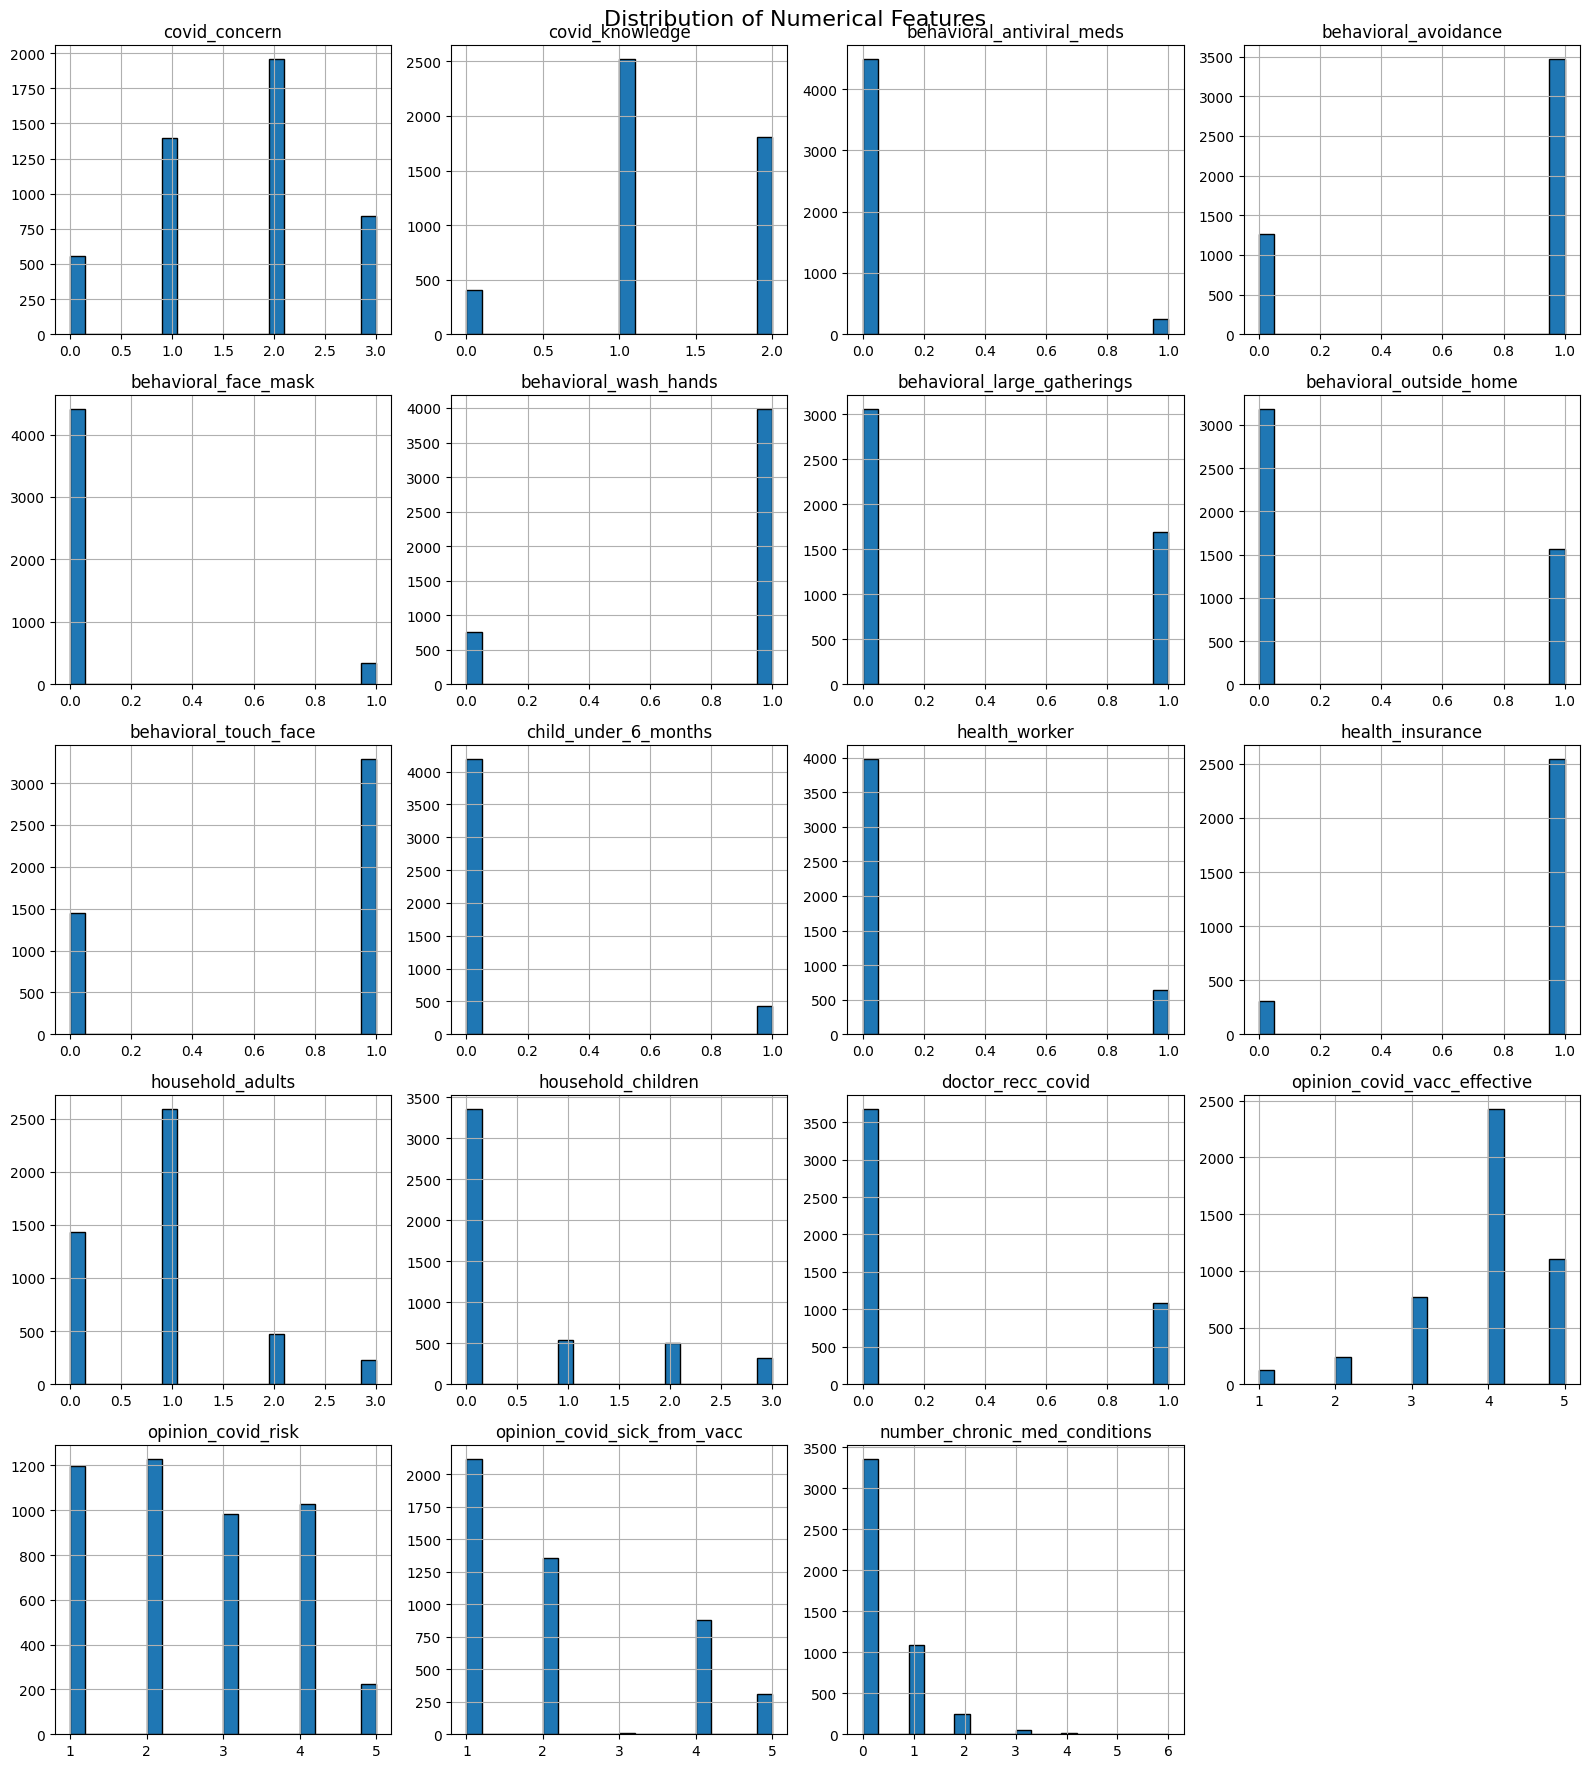

In [108]:

# Cell 11 – Visualise numerical features

# Exclude respondent ID and target variable
numerical_features = [
    col for col in numerical_columns
    if col not in ['respondent_id', 'covid_vaccine']
]

# Plot histograms
train[numerical_features].hist(
    figsize=(16, 18),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Numerical Features',
    fontsize=16
)

plt.tight_layout()
plt.show()


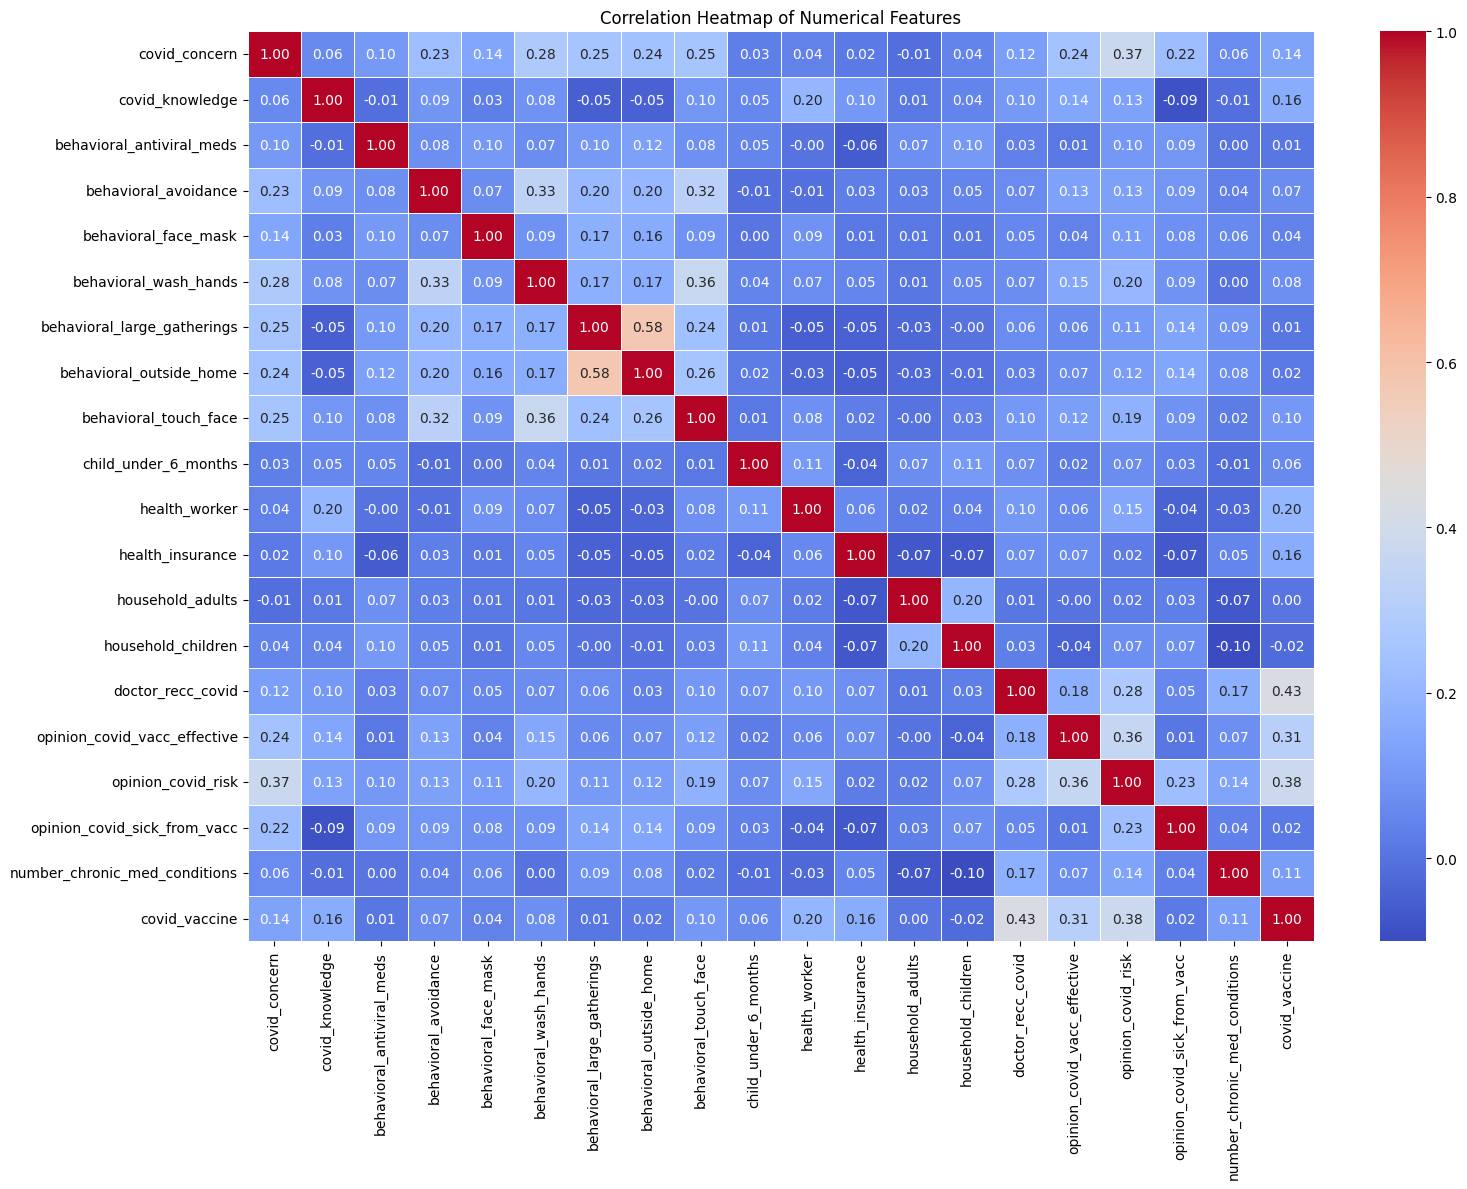

In [109]:

# Cell 12 – Correlation analysis

# Select numerical columns, excluding respondent ID
correlation_data = train.drop(
    columns=['respondent_id']
)

# Calculate correlations
correlation_matrix = correlation_data.corr(
    numeric_only=True
)

# Plot correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()

plt.savefig(
    'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


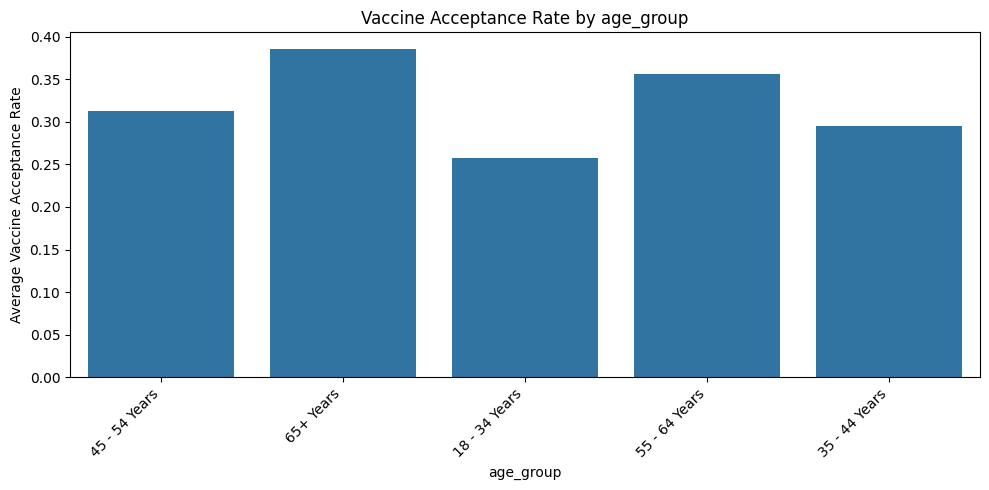

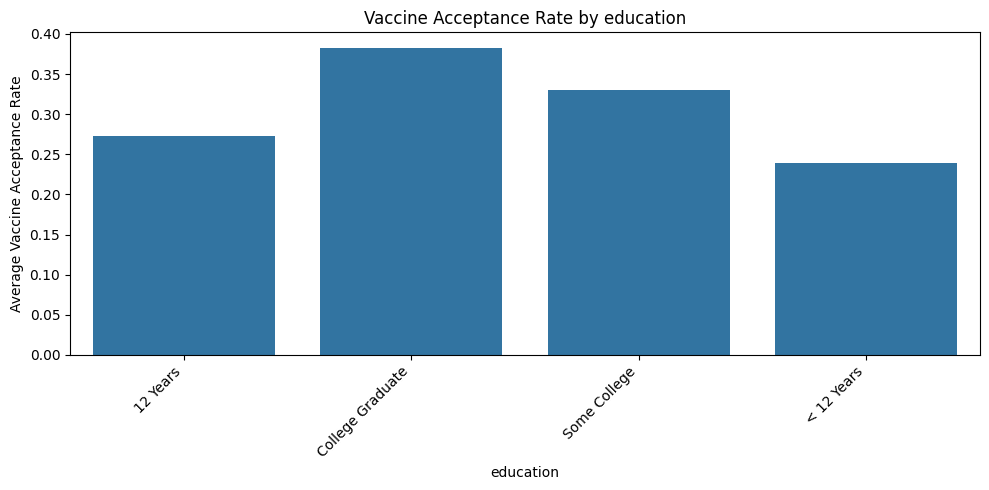

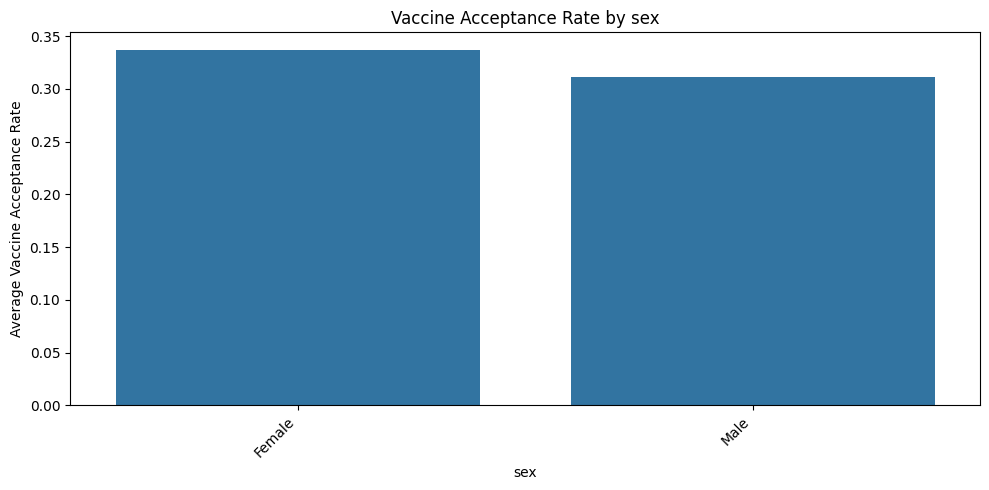

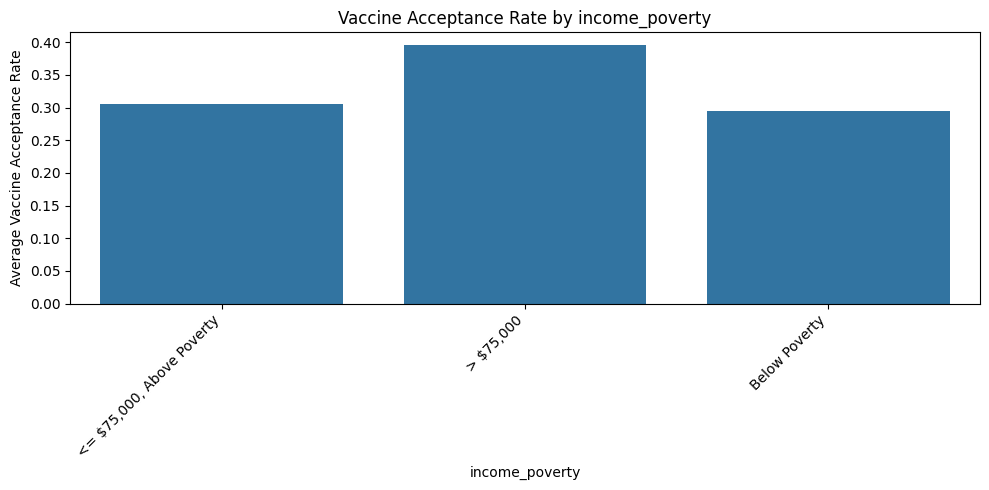

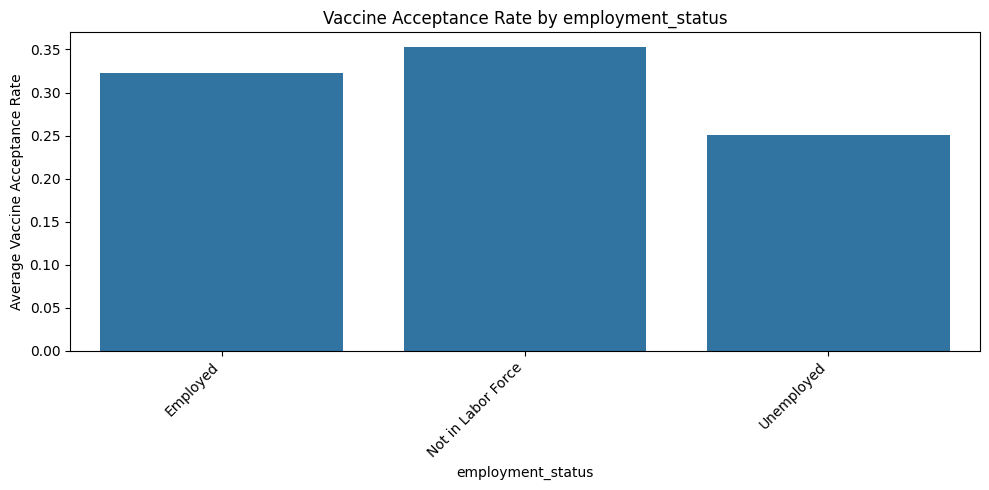

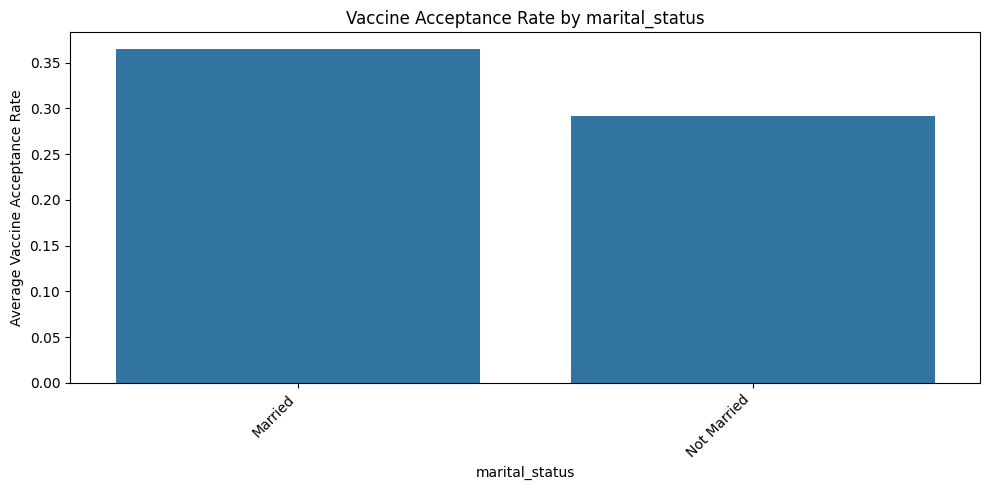

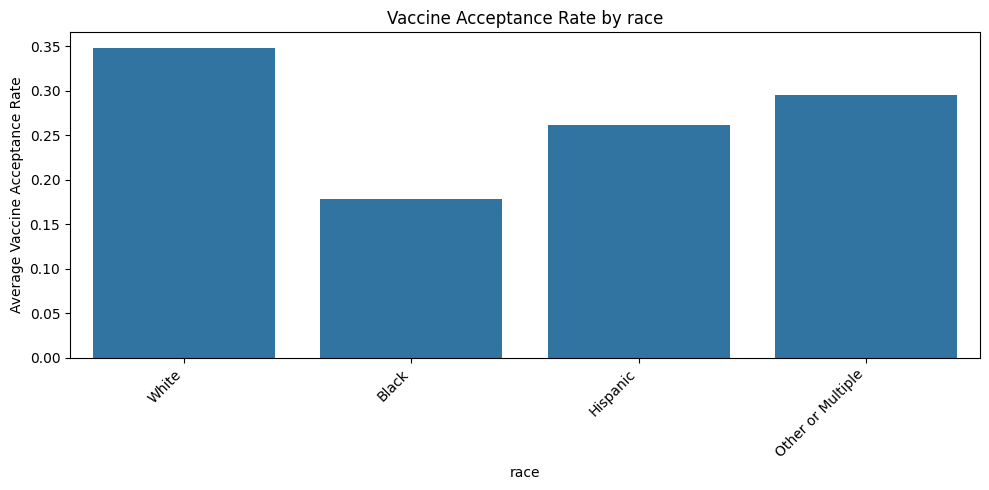

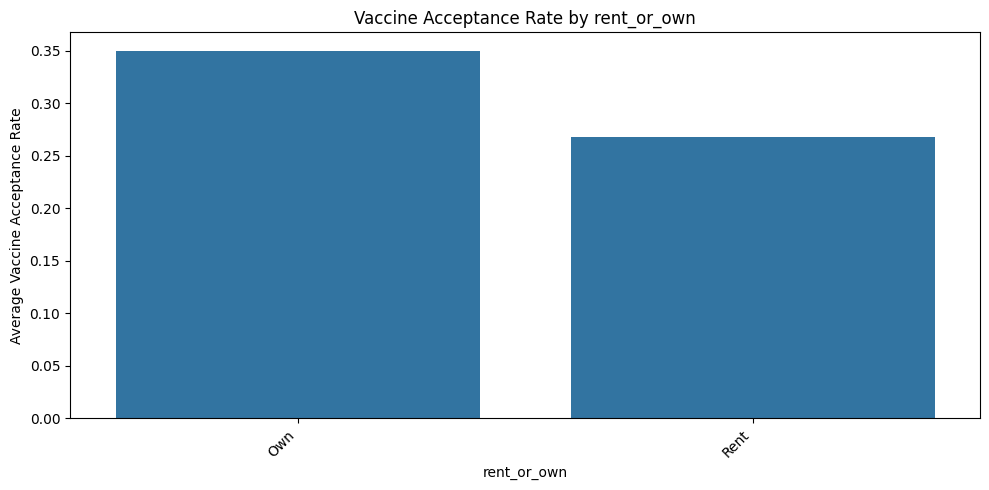

In [110]:

# Cell 13 – Categorical features vs COVID vaccine acceptance

selected_features = [
    'age_group',
    'education',
    'sex',
    'income_poverty',
    'employment_status',
    'marital_status',
    'race',
    'rent_or_own'
]

for col in selected_features:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=train,
        x=col,
        y='covid_vaccine',
        errorbar=None
    )

    plt.title(f'Vaccine Acceptance Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Vaccine Acceptance Rate')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()


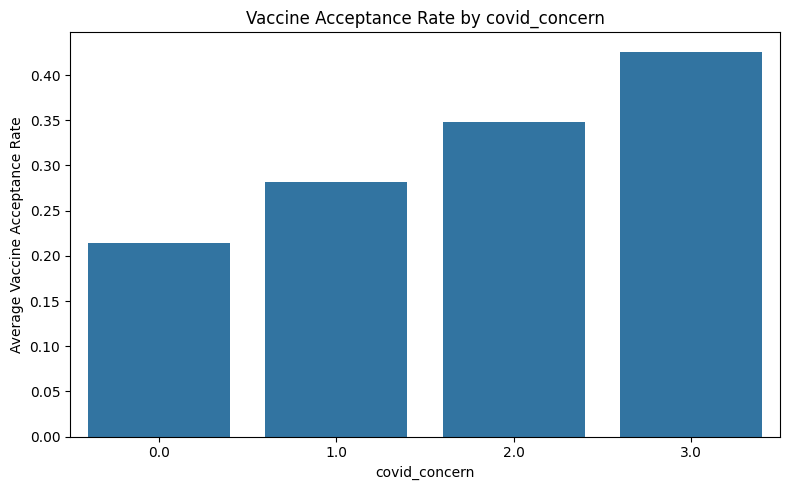

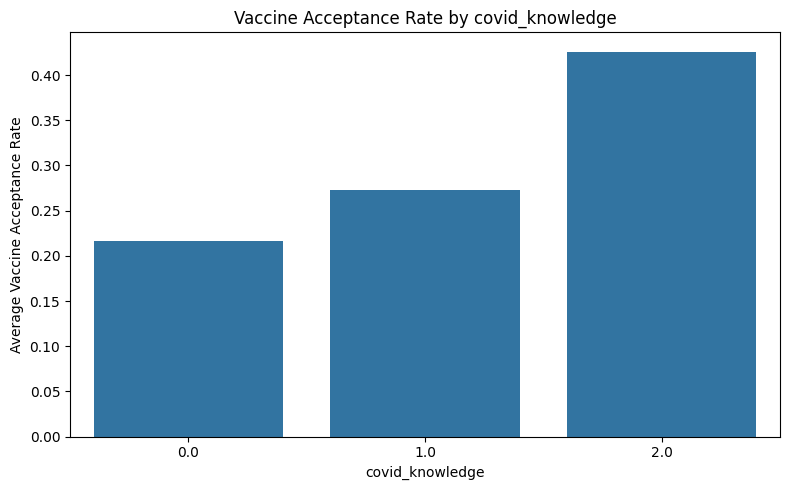

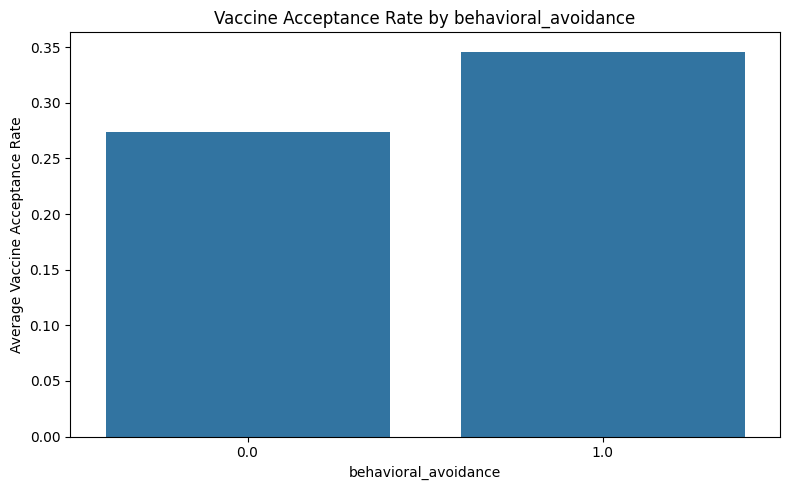

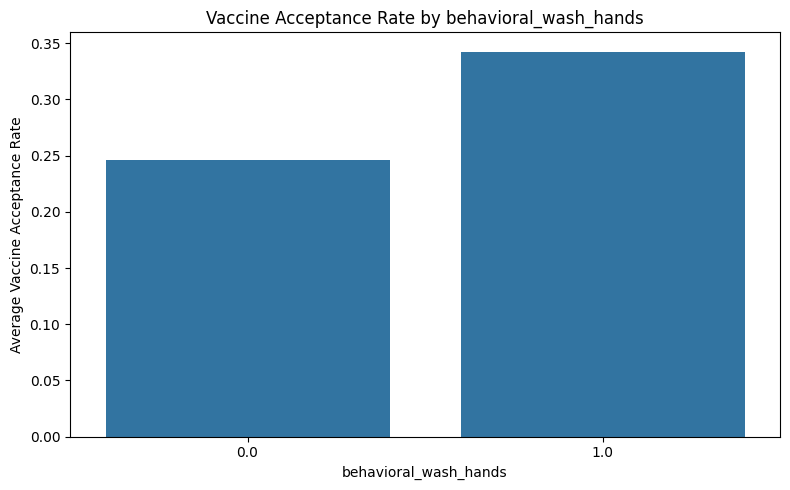

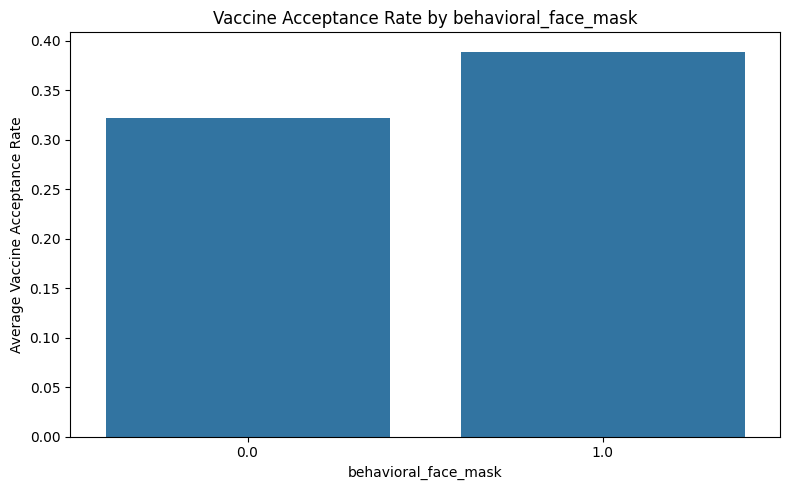

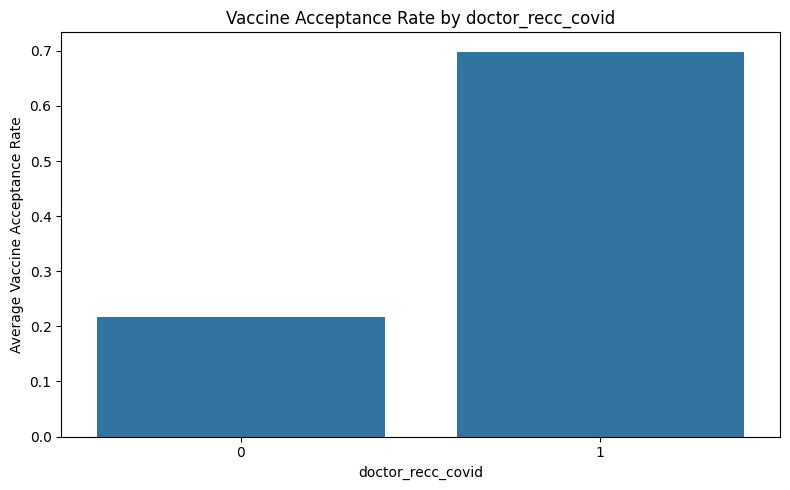

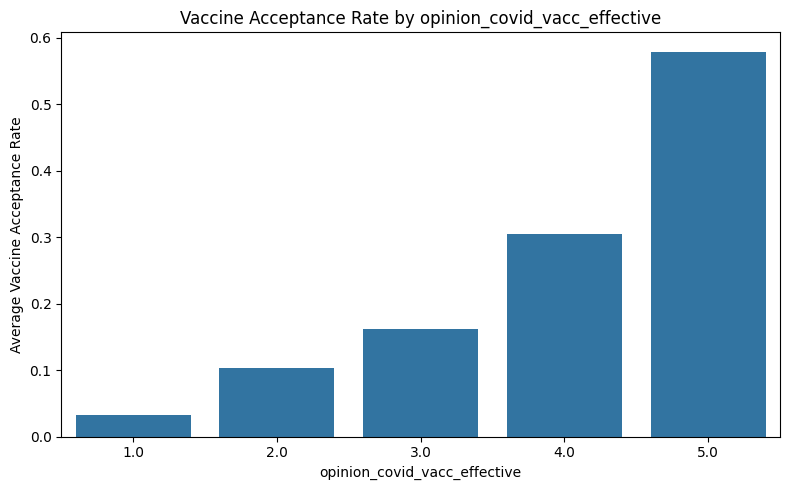

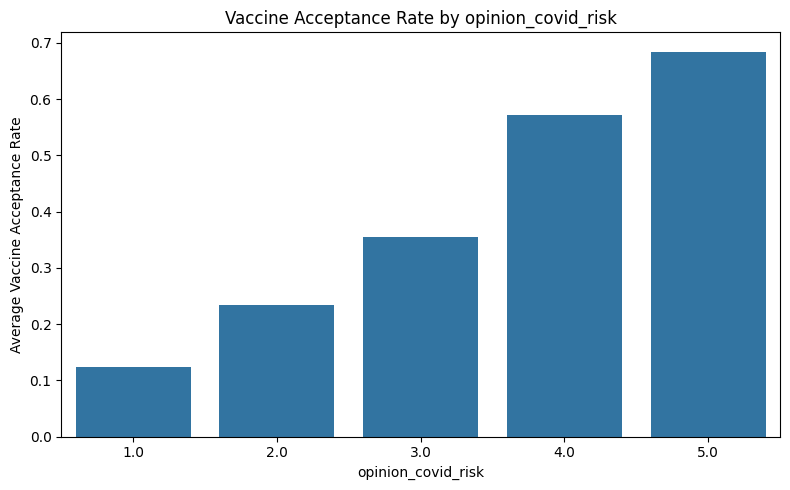

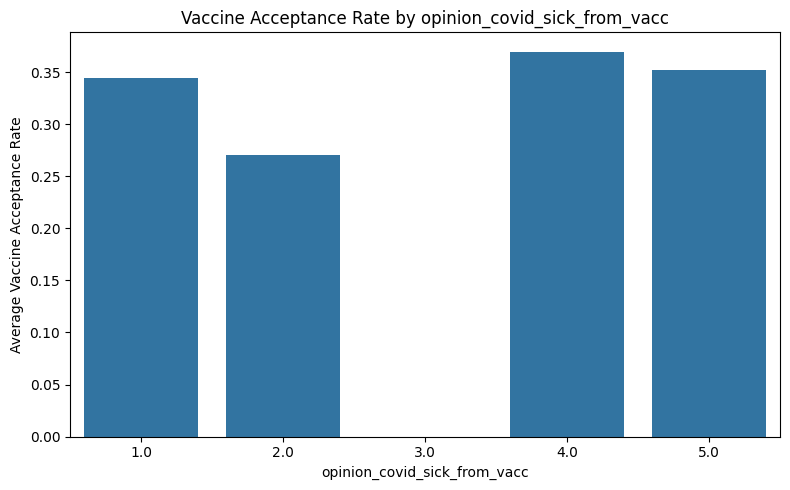

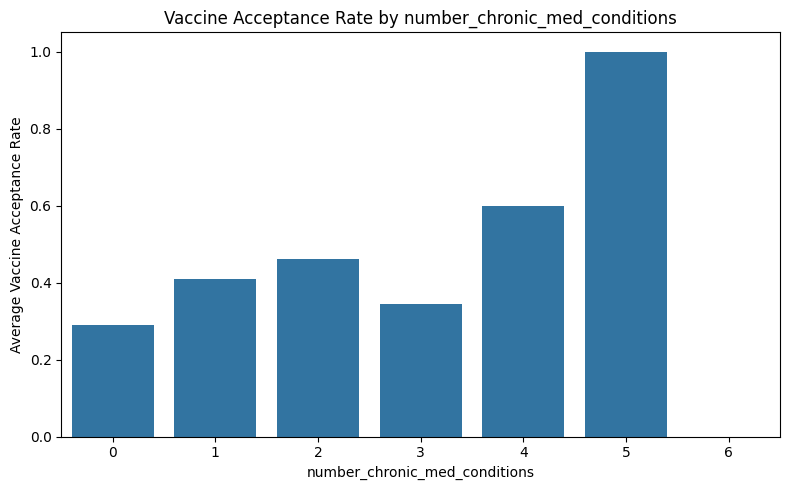

In [111]:

# Cell 14 – Numerical features vs COVID vaccine acceptance

selected_numerical = [
    'covid_concern',
    'covid_knowledge',
    'behavioral_avoidance',
    'behavioral_wash_hands',
    'behavioral_face_mask',
    'doctor_recc_covid',
    'opinion_covid_vacc_effective',
    'opinion_covid_risk',
    'opinion_covid_sick_from_vacc',
    'number_chronic_med_conditions'
]

for col in selected_numerical:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=train,
        x=col,
        y='covid_vaccine',
        errorbar=None
    )

    plt.title(f'Vaccine Acceptance Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Vaccine Acceptance Rate')

    plt.tight_layout()
    plt.show()


In [112]:
# Cell 15 – Check missing values in training and testing datasets

print("Missing values in training dataset:")
train_missing = train.isnull().sum()
display(train_missing[train_missing > 0].sort_values(ascending=False))

print("\nMissing values in testing dataset:")
test_missing = test.isnull().sum()
display(test_missing[test_missing > 0].sort_values(ascending=False))

Missing values in training dataset:


,0
employment_sector,2330
health_insurance,1908
income_poverty,748
rent_or_own,329
employment_status,238
marital_status,231
education,228
child_under_6_months,135
health_worker,132
opinion_covid_risk,96



Missing values in testing dataset:


,0
employment_sector,2405
health_insurance,1982
income_poverty,797
rent_or_own,379
employment_status,277
marital_status,269
education,269
child_under_6_months,155
health_worker,149
opinion_covid_sick_from_vacc,107


In [113]:

# Cell 16 – Separate features and target variable

# Remove respondent_id and target from training features
X = train.drop(
    columns=['respondent_id', 'covid_vaccine']
)

# Save target variable
y = train['covid_vaccine']

# Remove respondent_id from testing features
X_test = test.drop(
    columns=['respondent_id']
)

# Check dimensions
print("Training features shape:", X.shape)
print("Target variable shape:", y.shape)
print("Testing features shape:", X_test.shape)


Training features shape: (4756, 29)
Target variable shape: (4756,)
Testing features shape: (4749, 29)


In [114]:

# Cell 17 – Handle missing values

from sklearn.impute import SimpleImputer

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Create imputers
numerical_imputer = SimpleImputer(strategy='median')

categorical_imputer = SimpleImputer(strategy='most_frequent')

# Apply numerical imputation
X[numerical_features] = numerical_imputer.fit_transform(
    X[numerical_features]
)

X_test[numerical_features] = numerical_imputer.transform(
    X_test[numerical_features]
)

# Apply categorical imputation
X[categorical_features] = categorical_imputer.fit_transform(
    X[categorical_features]
)

X_test[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

print("Missing values after imputation:")
print("Training:", X.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())


Missing values after imputation:
Training: 0
Testing: 0


In [115]:

# Cell 18 – Encode categorical features

from sklearn.preprocessing import OneHotEncoder

# Create One-Hot Encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit encoder on training data
X_cat_encoded = encoder.fit_transform(X[categorical_features])

# Apply the same encoder to testing data
X_test_cat_encoded = encoder.transform(X_test[categorical_features])

# Convert encoded data into DataFrames
encoded_columns = encoder.get_feature_names_out(categorical_features)

X_cat_encoded = pd.DataFrame(
    X_cat_encoded,
    columns=encoded_columns,
    index=X.index
)

X_test_cat_encoded = pd.DataFrame(
    X_test_cat_encoded,
    columns=encoded_columns,
    index=X_test.index
)

# Remove original categorical columns
X = X.drop(columns=categorical_features)
X_test = X_test.drop(columns=categorical_features)

# Combine numerical and encoded categorical features
X = pd.concat([X, X_cat_encoded], axis=1)
X_test = pd.concat([X_test, X_test_cat_encoded], axis=1)

print("Training data shape after encoding:", X.shape)
print("Testing data shape after encoding:", X_test.shape)
print("Missing values in training:", X.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())


Training data shape after encoding: (4756, 68)
Testing data shape after encoding: (4749, 68)
Missing values in training: 0
Missing values in testing: 0


In [116]:

# Cell 19 – Split training and validation data

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)


Training features: (3804, 68)
Validation features: (952, 68)
Training target: (3804,)
Validation target: (952,)

Training target distribution:
covid_vaccine
0    67.32387
1    32.67613
Name: proportion, dtype: float64

Validation target distribution:
covid_vaccine
0    67.331933
1    32.668067
Name: proportion, dtype: float64


In [117]:

# Cell 20 – Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions on validation data
y_pred_lr = logistic_model.predict(X_val)

# Evaluate the model
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_val, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_lr))


Logistic Regression Results
Accuracy: 0.8035714285714286

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       641
           1       0.76      0.59      0.66       311

    accuracy                           0.80       952
   macro avg       0.79      0.75      0.76       952
weighted avg       0.80      0.80      0.80       952


Confusion Matrix:
[[583  58]
 [129 182]]


In [118]:

# Cell 21 – Rebuild raw features and split the data

from sklearn.model_selection import train_test_split

# Separate features and target again from original datasets
X = train.drop(columns=['respondent_id', 'covid_vaccine']).copy()
y = train['covid_vaccine'].copy()
X_test = test.drop(columns=['respondent_id']).copy()

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Split before imputation and encoding
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))


Training data: (3804, 29)
Validation data: (952, 29)
Testing data: (4749, 29)
Categorical features: 10
Numerical features: 19


In [119]:

# Cell 22 – Preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed testing shape:", X_test_processed.shape)



Processed training shape: (3804, 68)
Processed validation shape: (952, 68)
Processed testing shape: (4749, 68)


In [120]:

# Cell 23 – Logistic Regression with corrected preprocessing

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

# Predict validation data
y_pred_lr = logistic_model.predict(X_val_processed)

# Evaluate the model
print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_val, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_lr))



Logistic Regression Results
Accuracy: 0.8035714285714286

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       641
           1       0.76      0.59      0.66       311

    accuracy                           0.80       952
   macro avg       0.79      0.75      0.76       952
weighted avg       0.80      0.80      0.80       952


Confusion Matrix:
[[583  58]
 [129 182]]


In [121]:

# Cell 24 – Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

# Predict validation data
y_pred_rf = random_forest_model.predict(X_val_processed)

# Evaluate the model
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_val, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_rf))


Random Forest Results
Accuracy: 0.7836134453781513

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.92      0.85       641
           1       0.75      0.51      0.61       311

    accuracy                           0.78       952
   macro avg       0.77      0.71      0.73       952
weighted avg       0.78      0.78      0.77       952


Confusion Matrix:
[[587  54]
 [152 159]]


In [122]:

# Cell 25 – Linear SVM model

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Linear SVM model
svm_model = LinearSVC(
    C=1.0,
    class_weight='balanced',
    random_state=42,
    max_iter=5000
)

# Train the model
svm_model.fit(X_train_processed, y_train)

# Predict validation data
y_pred_svm = svm_model.predict(X_val_processed)

# Evaluate the model
print("Linear SVM Results")

print("Accuracy:", accuracy_score(y_val, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_svm))



Linear SVM Results
Accuracy: 0.7699579831932774

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       641
           1       0.62      0.74      0.68       311

    accuracy                           0.77       952
   macro avg       0.74      0.76      0.75       952
weighted avg       0.78      0.77      0.77       952


Confusion Matrix:
[[502 139]
 [ 80 231]]


In [123]:

# Cell 26 – K-Nearest Neighbours model

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    n_jobs=-1
)

# Train the model
knn_model.fit(X_train_processed, y_train)

# Predict validation data
y_pred_knn = knn_model.predict(X_val_processed)

# Evaluate the model
print("KNN Results")

print("Accuracy:", accuracy_score(y_val, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_knn))


KNN Results
Accuracy: 0.7510504201680672

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.87      0.82       641
           1       0.65      0.51      0.57       311

    accuracy                           0.75       952
   macro avg       0.72      0.69      0.70       952
weighted avg       0.74      0.75      0.74       952


Confusion Matrix:
[[557  84]
 [153 158]]


In [124]:

# Cell 27 – Compare all four machine learning models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Linear SVM',
        'KNN'
    ],
    'Accuracy': [
        accuracy_score(y_val, y_pred_lr),
        accuracy_score(y_val, y_pred_rf),
        accuracy_score(y_val, y_pred_svm),
        accuracy_score(y_val, y_pred_knn)
    ],
    'Class 1 Recall': [
        0.59, 0.51, 0.74, 0.51
    ],
    'False Positives': [58, 54, 139, 84],
    'False Negatives': [129, 152, 80, 153]
})

display(model_comparison.sort_values(
    by='Class 1 Recall',
    ascending=False
))



,Model,Accuracy,Class 1 Recall,False Positives,False Negatives
2,Linear SVM,0.769958,0.74,139,80
0,Logistic Regression,0.803571,0.59,58,129
1,Random Forest,0.783613,0.51,54,152
3,KNN,0.751050,0.51,84,153


In [125]:

# Cell 28 – Exact model comparison

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

predictions = {
    'Logistic Regression': y_pred_lr,
    'Random Forest': y_pred_rf,
    'Linear SVM': y_pred_svm,
    'KNN': y_pred_knn
}

results = []

for model_name, predictions_model in predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions_model
    ).ravel()

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, predictions_model),
        'Precision': precision_score(y_val, predictions_model),
        'Recall': recall_score(y_val, predictions_model),
        'F1 Score': f1_score(y_val, predictions_model),
        'False Positives': fp,
        'False Negatives': fn
    })

exact_comparison = pd.DataFrame(results)

display(
    exact_comparison.sort_values(
        by='Recall',
        ascending=False
    ).reset_index(drop=True)
)


,Model,Accuracy,Precision,Recall,F1 Score,False Positives,False Negatives
0,Linear SVM,0.769958,0.624324,0.742765,0.678414,139,80
1,Logistic Regression,0.803571,0.758333,0.585209,0.660617,58,129
2,Random Forest,0.783613,0.746479,0.511254,0.606870,54,152
3,KNN,0.751050,0.652893,0.508039,0.571429,84,153


In [126]:

# Cell 29 – Analyse potential hospitalisation risk factors

# Check age group distribution
print("Age Group Distribution:")
display(
    train['age_group'].value_counts(dropna=False).to_frame('Number of Respondents')
)

# Check chronic medical conditions
print("\nNumber of Chronic Medical Conditions:")
display(
    train['number_chronic_med_conditions']
    .value_counts(dropna=False)
    .sort_index()
    .to_frame('Number of Respondents')
)

# Summary of chronic medical conditions
print("\nChronic Medical Conditions Summary:")
display(
    train['number_chronic_med_conditions'].describe()
)


Age Group Distribution:


,Number of Respondents
age_group,
65+ Years,1208
55 - 64 Years,992
45 - 54 Years,948
18 - 34 Years,947
35 - 44 Years,661



Number of Chronic Medical Conditions:


,Number of Respondents
number_chronic_med_conditions,
0,3354
1,1083
2,249
3,58
4,10
5,1
6,1



Chronic Medical Conditions Summary:


,number_chronic_med_conditions
count,4756.000000
mean,0.379731
std,0.670265
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,6.000000


In [127]:

# Cell 30 – Analyse chronic conditions by age group

age_chronic_summary = train.groupby('age_group', observed=False).agg(
    Respondents=('number_chronic_med_conditions', 'count'),
    Average_Chronic_Conditions=('number_chronic_med_conditions', 'mean'),
    With_Chronic_Conditions=(
        'number_chronic_med_conditions',
        lambda x: (x > 0).sum()
    )
)

# Calculate the percentage with at least one chronic condition
age_chronic_summary['Percentage_With_Chronic_Conditions'] = (
    age_chronic_summary['With_Chronic_Conditions']
    / age_chronic_summary['Respondents'] * 100
)

display(age_chronic_summary.round(2))


,Respondents,Average_Chronic_Conditions,With_Chronic_Conditions,Percentage_With_Chronic_Conditions
age_group,,,,
18 - 34 Years,947,0.20,153,16.16
35 - 44 Years,661,0.25,133,20.12
45 - 54 Years,948,0.35,257,27.11
55 - 64 Years,992,0.46,344,34.68
65+ Years,1208,0.54,515,42.63


In [128]:

# Cell 30 - Research-based hospitalisation risk reference

hospitalisation_risk = pd.DataFrame({
    'age_group': [
        '18 - 34 Years',
        '35 - 44 Years',
        '45 - 54 Years',
        '55 - 64 Years',
        '65 - 74 Years',
        '75+ Years'
    ],
    'hospitalisation_risk_percent': [
        0.0317,
        0.0400,
        0.0763,
        0.208,
        0.686,
        3.28
    ]
})

print("Research-based hospitalisation risk by age:")
display(hospitalisation_risk)


Research-based hospitalisation risk by age:


,age_group,hospitalisation_risk_percent
0,18 - 34 Years,0.0317
1,35 - 44 Years,0.0400
2,45 - 54 Years,0.0763
3,55 - 64 Years,0.2080
4,65 - 74 Years,0.6860
5,75+ Years,3.2800


In [129]:

# Cell 31 - Match hospitalisation risks to dataset age groups

# Convert research percentages into probabilities
age_risk_mapping = {
    '18 - 34 Years': 0.0317 / 100,
    '35 - 44 Years': 0.0400 / 100,
    '45 - 54 Years': 0.0763 / 100,
    '55 - 64 Years': 0.2080 / 100,
    '65+ Years': 0.6860 / 100
}

# Create a copy of the training data
risk_data = train.copy()

# Assign the research-based risk to each respondent
risk_data['baseline_hospitalisation_probability'] = (
    risk_data['age_group'].map(age_risk_mapping)
)

print("Hospitalisation probability by age group:")
display(
    risk_data.groupby('age_group')[
        'baseline_hospitalisation_probability'
    ].first().to_frame()
)

print("\nMissing risk probabilities:")
print(risk_data['baseline_hospitalisation_probability'].isna().sum())


Hospitalisation probability by age group:


,baseline_hospitalisation_probability
age_group,
18 - 34 Years,0.000317
35 - 44 Years,0.000400
45 - 54 Years,0.000763
55 - 64 Years,0.002080
65+ Years,0.006860



Missing risk probabilities:
0


In [130]:

# Cell 32 - Examine chronic conditions by age group

risk_data['has_chronic_condition'] = (
    risk_data['number_chronic_med_conditions'] > 0
).astype(int)

chronic_risk_summary = (
    risk_data.groupby('age_group')
    .agg(
        Respondents=('age_group', 'count'),
        With_Chronic_Conditions=('has_chronic_condition', 'sum'),
        Average_Chronic_Conditions=('number_chronic_med_conditions', 'mean'),
        Baseline_Hospitalisation_Risk=(
            'baseline_hospitalisation_probability', 'first'
        )
    )
)

chronic_risk_summary['Percentage_With_Chronic_Conditions'] = (
    chronic_risk_summary['With_Chronic_Conditions']
    / chronic_risk_summary['Respondents'] * 100
)

display(chronic_risk_summary.round(4))



,Respondents,With_Chronic_Conditions,Average_Chronic_Conditions,Baseline_Hospitalisation_Risk,Percentage_With_Chronic_Conditions
age_group,,,,,
18 - 34 Years,947,153,0.2049,0.0003,16.1563
35 - 44 Years,661,133,0.2466,0.0004,20.1210
45 - 54 Years,948,257,0.3502,0.0008,27.1097
55 - 64 Years,992,344,0.4637,0.0021,34.6774
65+ Years,1208,515,0.5439,0.0069,42.6325


In [131]:

# Cell 33 - Calculate vaccine costs

VACCINE_COST = 1500

predictions = {
    'Logistic Regression': y_pred_lr,
    'Random Forest': y_pred_rf,
    'Linear SVM': y_pred_svm,
    'KNN': y_pred_knn
}

vaccine_cost_results = []

for model_name, y_pred in predictions.items():

    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()

    vaccines_sent = tp + fp
    compensation_required = fn

    total_vaccine_cost = (
        vaccines_sent + compensation_required
    ) * VACCINE_COST

    vaccine_cost_results.append({
        'Model': model_name,
        'Vaccines_Sent': vaccines_sent,
        'Wasted_Vaccines': fp,
        'Compensation_Required': compensation_required,
        'Total_Vaccine_Cost': total_vaccine_cost
    })

vaccine_cost_comparison = pd.DataFrame(vaccine_cost_results)

display(
    vaccine_cost_comparison.sort_values(
        by='Total_Vaccine_Cost'
    ).reset_index(drop=True)
)


,Model,Vaccines_Sent,Wasted_Vaccines,Compensation_Required,Total_Vaccine_Cost
0,Random Forest,213,54,152,547500
1,Logistic Regression,240,58,129,553500
2,KNN,242,84,153,592500
3,Linear SVM,370,139,80,675000


In [132]:

# Cell 34 - Calculate expected hospitalisation costs

HOSPITALISATION_COST = 41000
VACCINE_EFFECTIVENESS = 0.55

# Get baseline risks for validation respondents
validation_risk = risk_data.loc[y_val.index,
    'baseline_hospitalisation_probability']

hospital_cost_results = []

for model_name, y_pred in predictions.items():

    # A vaccine is actually used only when both are 1
    actually_vaccinated = (y_val == 1) & (y_pred == 1)

    # Start with baseline hospitalisation probabilities
    individual_risk = validation_risk.copy()

    # Reduce risk for people who actually receive the vaccine
    individual_risk.loc[actually_vaccinated] *= (
        1 - VACCINE_EFFECTIVENESS
    )

    # Calculate expected hospitalisations and cost
    expected_hospitalisations = individual_risk.sum()

    expected_hospitalisation_cost = (
        expected_hospitalisations * HOSPITALISATION_COST
    )

    hospital_cost_results.append({
        'Model': model_name,
        'Actually_Vaccinated': actually_vaccinated.sum(),
        'Expected_Hospitalisations': expected_hospitalisations,
        'Expected_Hospitalisation_Cost':
            expected_hospitalisation_cost
    })

hospital_cost_comparison = pd.DataFrame(hospital_cost_results)

display(
    hospital_cost_comparison.sort_values(
        by='Expected_Hospitalisation_Cost'
    ).reset_index(drop=True).round(2)
)


,Model,Actually_Vaccinated,Expected_Hospitalisations,Expected_Hospitalisation_Cost
0,Linear SVM,231,2.05,83969.67
1,Logistic Regression,182,2.12,86932.81
2,KNN,158,2.16,88606.54
3,Random Forest,159,2.17,88914.57


In [133]:

# Cell 35 - Calculate total town cost

total_cost_comparison = pd.merge(
    vaccine_cost_comparison,
    hospital_cost_comparison,
    on='Model'
)

total_cost_comparison['Total_Town_Cost'] = (
    total_cost_comparison['Total_Vaccine_Cost']
    + total_cost_comparison['Expected_Hospitalisation_Cost']
)

total_cost_comparison = total_cost_comparison.sort_values(
    by='Total_Town_Cost'
).reset_index(drop=True)

display(total_cost_comparison.round(2))


,Model,Vaccines_Sent,Wasted_Vaccines,Compensation_Required,Total_Vaccine_Cost,Actually_Vaccinated,Expected_Hospitalisations,Expected_Hospitalisation_Cost,Total_Town_Cost
0,Random Forest,213,54,152,547500,159,2.17,88914.57,636414.57
1,Logistic Regression,240,58,129,553500,182,2.12,86932.81,640432.81
2,KNN,242,84,153,592500,158,2.16,88606.54,681106.54
3,Linear SVM,370,139,80,675000,231,2.05,83969.67,758969.67


In [134]:

# Cell 36 - Optimise Logistic Regression threshold

VACCINE_COST = 1500
HOSPITALISATION_COST = 41000
VACCINE_EFFECTIVENESS = 0.55

# Get predicted probabilities
lr_probabilities = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    # Convert probabilities into predictions
    threshold_predictions = (
        lr_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val, threshold_predictions
    ).ravel()

    # Calculate vaccine costs
    vaccines_sent = tp + fp
    compensation_required = fn

    vaccine_cost = (
        vaccines_sent + compensation_required
    ) * VACCINE_COST

    # Identify people who actually receive and use vaccines
    actually_vaccinated = (
        (y_val == 1) & (threshold_predictions == 1)
    )

    # Calculate expected hospitalisations
    individual_risk = validation_risk.copy()

    individual_risk.loc[actually_vaccinated] *= (
        1 - VACCINE_EFFECTIVENESS
    )

    expected_hospitalisations = individual_risk.sum()

    hospitalisation_cost = (
        expected_hospitalisations * HOSPITALISATION_COST
    )

    # Calculate total town cost
    total_town_cost = vaccine_cost + hospitalisation_cost

    threshold_results.append({
        'Threshold': threshold,
        'Vaccine_Cost': vaccine_cost,
        'Hospitalisation_Cost': hospitalisation_cost,
        'Expected_Hospitalisations': expected_hospitalisations,
        'Total_Town_Cost': total_town_cost
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(
    threshold_comparison.sort_values(
        by='Total_Town_Cost'
    ).reset_index(drop=True).round(2)
)


,Threshold,Vaccine_Cost,Hospitalisation_Cost,Expected_Hospitalisations,Total_Town_Cost
0,0.90,471000,98546.47,2.40,569546.47
1,0.85,480000,97357.05,2.37,577357.05
2,0.80,487500,95361.30,2.33,582861.30
3,0.75,495000,94163.45,2.30,589163.45
4,0.70,502500,92958.17,2.27,595458.17
5,0.65,508500,90973.32,2.22,599473.32
6,0.60,526500,88841.96,2.17,615341.96
7,0.55,537000,88315.06,2.15,625315.06
8,0.50,553500,86932.81,2.12,640432.81
9,0.45,582000,85690.69,2.09,667690.69


In [135]:

# Cell 37 - Test thresholds between 0.90 and 1.00

fine_threshold_results = []

for threshold in np.arange(0.90, 1.001, 0.01):

    threshold_predictions = (
        lr_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, threshold_predictions
    ).ravel()

    vaccine_cost = (tp + fp + fn) * VACCINE_COST

    actually_vaccinated = (
        (y_val == 1) & (threshold_predictions == 1)
    )

    individual_risk = validation_risk.copy()

    individual_risk.loc[actually_vaccinated] *= (
        1 - VACCINE_EFFECTIVENESS
    )

    expected_hospitalisations = individual_risk.sum()

    hospitalisation_cost = (
        expected_hospitalisations * HOSPITALISATION_COST
    )

    total_cost = vaccine_cost + hospitalisation_cost

    fine_threshold_results.append({
        'Threshold': round(threshold, 2),
        'Vaccine_Cost': vaccine_cost,
        'Hospitalisation_Cost': hospitalisation_cost,
        'Expected_Hospitalisations': expected_hospitalisations,
        'Total_Town_Cost': total_cost
    })

fine_threshold_comparison = pd.DataFrame(fine_threshold_results)

display(
    fine_threshold_comparison.sort_values(
        'Total_Town_Cost'
    ).reset_index(drop=True).round(2)
)


,Threshold,Vaccine_Cost,Hospitalisation_Cost,Expected_Hospitalisations,Total_Town_Cost
0,0.97,466500,100376.83,2.45,566876.83
1,1.00,466500,100394.03,2.45,566894.04
2,0.99,466500,100394.03,2.45,566894.04
3,0.98,466500,100394.03,2.45,566894.04
4,0.93,468000,99490.55,2.43,567490.55
5,0.94,468000,99799.93,2.43,567799.93
6,0.95,468000,99978.98,2.44,567978.98
7,0.96,468000,100214.99,2.44,568214.99
8,0.92,469500,99061.13,2.42,568561.13
9,0.90,471000,98546.47,2.40,569546.47


In [136]:

# Check the model variables available
print([name for name in globals() if "model" in name.lower()])


['logistic_model', 'random_forest_model', 'svm_model', 'knn_model', 'model_comparison', 'model_name', 'predictions_model', 'model_probabilities', 'all_model_results', 'all_model_results_df', 'final_model']


In [137]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

# Convert Linear SVM scores into probabilities
calibrated_svm = CalibratedClassifierCV(svm_model, cv=3)
calibrated_svm.fit(X_train_processed, y_train)

# Get prediction probabilities from all four models
model_probabilities = {
    "Logistic Regression": logistic_model.predict_proba(X_val_processed)[:, 1],
    "Random Forest": random_forest_model.predict_proba(X_val_processed)[:, 1],
    "Linear SVM": calibrated_svm.predict_proba(X_val_processed)[:, 1],
    "KNN": knn_model.predict_proba(X_val_processed)[:, 1]
}

all_model_results = []

for model_name, probabilities in model_probabilities.items():

    for threshold in np.arange(0.01, 1.001, 0.01):

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        vaccine_cost = (tp + fp + fn) * VACCINE_COST

        actually_vaccinated = (y_val == 1) & (predictions == 1)

        individual_risk = validation_risk.copy()
        individual_risk.loc[actually_vaccinated] *= (
            1 - VACCINE_EFFECTIVENESS
        )

        expected_hospitalisations = individual_risk.sum()
        hospitalisation_cost = (
            expected_hospitalisations * HOSPITALISATION_COST
        )

        total_cost = vaccine_cost + hospitalisation_cost

        all_model_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Vaccine_Cost": vaccine_cost,
            "Hospitalisation_Cost": round(hospitalisation_cost, 2),
            "Expected_Hospitalisations": round(
                expected_hospitalisations, 4
            ),
            "Total_Town_Cost": round(total_cost, 2)
        })

all_model_results_df = pd.DataFrame(all_model_results)

best_combinations = all_model_results_df.sort_values(
    "Total_Town_Cost"
).head(5)

display(best_combinations)


,Model,Threshold,Vaccine_Cost,Hospitalisation_Cost,Expected_Hospitalisations,Total_Town_Cost
295,Linear SVM,0.96,466500,100376.83,2.4482,566876.83
96,Logistic Regression,0.97,466500,100376.83,2.4482,566876.83
299,Linear SVM,1.00,466500,100394.03,2.4486,566894.04
298,Linear SVM,0.99,466500,100394.03,2.4486,566894.04
297,Linear SVM,0.98,466500,100394.03,2.4486,566894.04


In [138]:
best_result = all_model_results_df.loc[
    all_model_results_df["Total_Town_Cost"].idxmin()
]

display(best_result)

,96
Model,Logistic Regression
Threshold,0.97
Vaccine_Cost,466500
Hospitalisation_Cost,100376.83
Expected_Hospitalisations,2.4482
Total_Town_Cost,566876.83


In [139]:

# Prepare training and testing data
X_train_final_processed = preprocessor.fit_transform(X)
X_test_final_processed = preprocessor.transform(X_test)

# Train final Logistic Regression model
final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_train_final_processed, y)

# Predict probabilities for test data
test_probabilities = final_model.predict_proba(
    X_test_final_processed
)[:, 1]

# Apply selected threshold
best_threshold = 0.97
test_predictions = (
    test_probabilities >= best_threshold
).astype(float)

# Check predictions
print("Prediction counts:")
print(pd.Series(test_predictions).value_counts())

print("Total predictions:", len(test_predictions))


Prediction counts:
0.0    4737
1.0      12
Name: count, dtype: int64
Total predictions: 4749


In [140]:

# Create submission file
submission = pd.DataFrame({
    "respondent_id": test["respondent_id"],
    "covid_vaccine": test_predictions.astype(float)
})

# Check the submission
print(submission.head(10))
print("\nSubmission shape:", submission.shape)
print("\nMissing values:")
print(submission.isnull().sum())

# Save as CSV
submission.to_csv("challenge_submission_group_o_order_4.csv", index=False)

print("\nSubmission file saved successfully!")


   respondent_id  covid_vaccine
0           4757            0.0
1           4758            0.0
2           4759            0.0
3           4760            0.0
4           4761            0.0
5           4762            0.0
6           4763            0.0
7           4764            0.0
8           4765            0.0
9           4766            0.0

Submission shape: (4749, 2)

Missing values:
respondent_id    0
covid_vaccine    0
dtype: int64

Submission file saved successfully!
